# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** Lina María Castro
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 💳 **Inclusión financiera y pobreza: ¿el acceso al crédito formal está asociado con mejores condiciones de bienestar en los hogares rurales de Colombia?**

**Notebook 2 de 2: modelos de clasificación**

**Integrantes:** Isabella Ramirez Santamaria, Kevin Stiven Albarracin González, Julián Eduardo Lizarazo Caceres, Juan Felipe Pacheco Gómez.

---

Este notebook parte de la base que genera `01_limpieza_eda.ipynb` y responde las dos preguntas que dejó abiertas el análisis exploratorio.

**Modelo 1. ¿Quién tiene crédito formal?** Variable objetivo: `credito_formal`. Población: todos los adultos, para poder comparar lo rural con las ciudades.

**Modelo 2. ¿El crédito formal se asocia con más resiliencia en los hogares rurales?** Variable objetivo: `aguanta_un_mes_o_mas`, que vale 1 si la persona podría vivir un mes o más sin ingresos. Población: adultos de municipios rurales y rurales dispersos.

Los dos son problemas de **clasificación binaria con clases desbalanceadas**, así que seguimos el mismo procedimiento del notebook de clases desbalanceadas:

1. Regresión Logística (con `class_weight`)
2. Árbol de Decisión (con `class_weight`)
3. Random Forest (con `class_weight`)
4. XGBoost (con `scale_pos_weight`)

**Métrica de Evaluación Principal:** AUC-ROC.

**Importante:** los modelos miden **asociaciones**, no efectos causales, porque los datos son de corte transversal.

## 1. Importación de Librerías y Carga de Datos

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

# Si el notebook se abre desde la carpeta notebooks/ del repositorio, se trabaja desde la raíz del proyecto
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Modelos
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Métricas y Tuning
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import shap

### Mejorar visualización de dataframes y gráficos

In [2]:
# Que muestre todas las columnas
pd.options.display.max_columns = None
# En los dataframes, mostrar los float con dos decimales
pd.options.display.float_format = '{:,.2f}'.format

# Configuraciones para una mejor visualización
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# Carpeta de figuras, la misma del notebook 1
os.makedirs('outputs/figures', exist_ok=True)
os.makedirs('outputs/tables', exist_ok=True)

def guardar(nombre):
    plt.savefig(f'outputs/figures/{nombre}.png', dpi=150, bbox_inches='tight')

### Carga de datos

In [3]:
# Base procesada que genera el notebook 01_limpieza_eda.ipynb
df = pd.read_csv('data/processed/base_inclusion_financiera_2022.csv')
print(df.shape)
df.head()

(5532, 59)


,cod_mpio,municipio,cod_dpto,departamento,region,ruralidad,rural,area,peso,credito_formal,credito_informal,solicito_credito,credito_negado,gota_a_gota,uso_consumo,uso_productivo,uso_vivienda_vehiculo,ahorro_formal,ahorro_digital,ahorro_informal,no_ahorra,ingreso_rango,ingreso_hogar,ingreso_smmlv,log_ingreso,segmento_ingreso,gasto_hogar,gasta_mas_que_gana,indice_bienestar,meses_resiliencia,aguanta_un_mes_o_mas,indice_activos,sexo,mujer,edad,jefe_hogar,educacion,educ_superior,actividad,ocupado,cuenta_propia,trabaja_agro,ingreso_irregular,estrato,menores_hogar,ocupados_hogar,ocupados_estables,usa_internet,cocina_con_lena,barrera: No le gusta endeudarse,barrera: Lo considera costoso,barrera: No se ajusta a sus necesidades,barrera: No lo considera útil,barrera: Reportado en centrales de riesgo,barrera: No tiene garantías,barrera: Ingresos bajos / no puede responder,barrera: No entiende cómo funciona,barrera: Piden muchos requisitos,barrera: No tiene historial crediticio
0,5001,Medellín,5,Antioquia,Eje Cafetero,Ciudades y aglomeraciones,0,Ciudades e intermedios,"11,450.00",0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,0.00,1.00,0.00,Entre 500.001 y 750.000,"625,000.00",0.62,13.35,"0,5-1 SM","1,250,000.00",1.00,41.67,0.25,0.00,4.00,Femenino,1.00,35,0.00,Secundaria,0.00,Oficios del hogar,0.00,0.00,0.00,1.00,1.00,2,2.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
1,5001,Medellín,5,Antioquia,Eje Cafetero,Ciudades y aglomeraciones,0,Ciudades e intermedios,"4,024.34",0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,0.00,0.00,1.00,Entre 750.001 y 1.000.000,"875,000.00",0.88,13.68,"0,5-1 SM","375,000.00",0.00,29.17,1.00,1.00,6.00,Femenino,1.00,48,1.00,Primaria,0.00,Oficios del hogar,0.00,0.00,0.00,1.00,1.00,2,0.00,1.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00
2,5001,Medellín,5,Antioquia,Eje Cafetero,Ciudades y aglomeraciones,0,Ciudades e intermedios,"10,369.24",1.00,0.00,1.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,Entre 500.001 y 750.000,"625,000.00",0.62,13.35,"0,5-1 SM","625,000.00",0.00,35.42,1.00,1.00,4.00,Femenino,1.00,69,1.00,Primaria,0.00,Oficios del hogar,0.00,0.00,0.00,0.00,1.00,0,1.00,0.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11001,"Bogotá, D.C.",11,"Bogotá, D.C.",Centro Oriente,Ciudades y aglomeraciones,0,Ciudades e intermedios,"6,544.89",0.00,0.00,0.00,0.00,0.00,NaN,NaN,NaN,0.00,0.00,1.00,0.00,Entre 500.001 y 750.000,"625,000.00",0.62,13.35,"0,5-1 SM","625,000.00",0.00,47.92,18.00,1.00,2.00,Femenino,1.00,41,1.00,Secundaria,0.00,Oficios del hogar,0.00,0.00,0.00,1.00,NaN,1,1.00,1.00,1.00,0.00,1.00,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
4,76001,Cali,76,Valle Del Cauca,Pacífico,Ciudades y aglomeraciones,0,Ciudades e intermedios,"33,366.72",1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,Entre 3.000.001 y 4.000.000,"3,500,000.00",3.50,15.07,> 2 SM,"6,000,000.00",1.00,41.67,0.25,0.00,6.00,Femenino,1.00,32,1.00,Tecnólogos,1.00,Oficios del hogar,0.00,0.00,0.00,0.00,4.00,3,2.00,2.00,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Preprocesamiento

### 2.1. Variables explicativas

Usamos solo **características de partida** de la persona y su hogar. No incluimos variables del proceso de crédito (si pidió crédito, si se lo negaron o en qué entidad), porque eso sería fuga de información: el modelo "sabría" la respuesta.

La educación viene como categoría ordenada, así que se convierte a un número de 0 (ninguna) a 6 (posgrado) con un diccionario y `.map()`, como en el taller de limpieza.

In [4]:
dic_educacion = {'Ninguno': 0, 'Primaria': 1, 'Secundaria': 2, 'Técnico': 3, 'Tecnólogos': 4, 'Universitarios': 5, 'Posgrado': 6}
df['educ_orden'] = df['educacion'].map(dic_educacion)

# Variables numéricas (se estandarizan)
num_cols = ['ingreso_smmlv', 'indice_activos', 'edad', 'educ_orden', 'estrato', 'menores_hogar']

# Variables binarias 0/1 (no se estandarizan, para que su odds ratio se lea como "tener la característica")
bin_cols = ['ocupado', 'cuenta_propia', 'trabaja_agro', 'ingreso_irregular', 'mujer', 'jefe_hogar',
            'usa_internet', 'cocina_con_lena']

# Variable categórica (One-Hot Encoding)
cat_cols = ['ruralidad']

print(f"Columnas Numéricas ({len(num_cols)}): {num_cols}")
print(f"Columnas Binarias ({len(bin_cols)}): {bin_cols}")
print(f"Columnas Categóricas ({len(cat_cols)}): {cat_cols}")

Columnas Numéricas (6): ['ingreso_smmlv', 'indice_activos', 'edad', 'educ_orden', 'estrato', 'menores_hogar']
Columnas Binarias (8): ['ocupado', 'cuenta_propia', 'trabaja_agro', 'ingreso_irregular', 'mujer', 'jefe_hogar', 'usa_internet', 'cocina_con_lena']
Columnas Categóricas (1): ['ruralidad']


### 2.2. Valores faltantes

In [5]:
print("Valores Nulos por Columna:")
print(df[num_cols + bin_cols + cat_cols].isnull().sum())

Valores Nulos por Columna:
ingreso_smmlv        230
indice_activos         0
edad                   0
educ_orden             4
estrato              243
menores_hogar          0
ocupado                0
cuenta_propia          0
trabaja_agro           0
ingreso_irregular    388
mujer                  0
jefe_hogar             0
usa_internet          28
cocina_con_lena        3
ruralidad              0
dtype: int64


Los faltantes vienen de respuestas "No sabe / No responde" que en el notebook 1 se convirtieron en nulos (ingreso, estrato y regularidad del ingreso). Como son pocos en cada variable, **eliminamos las filas con algún valor nulo** en las variables del modelo, como en el notebook de regresión polinómica.

---
## 3. Modelo 1: ¿Quién tiene crédito formal?

### 3.1. Definición de X/y

In [6]:
df_m1 = df[num_cols + bin_cols + cat_cols + ['credito_formal']].dropna()
print(f"Filas antes: {df.shape[0]} | Filas después de eliminar nulos: {df_m1.shape[0]}")

# Separar X (features) e y (target)
X1 = df_m1.drop('credito_formal', axis=1)
y1 = df_m1['credito_formal'].astype(int)

Filas antes: 5532 | Filas después de eliminar nulos: 4735


### 3.2. El Problema: Clases Desbalanceadas

credito_formal
0    3622
1    1113
Name: count, dtype: int64

Porcentaje con crédito formal: 23.51%


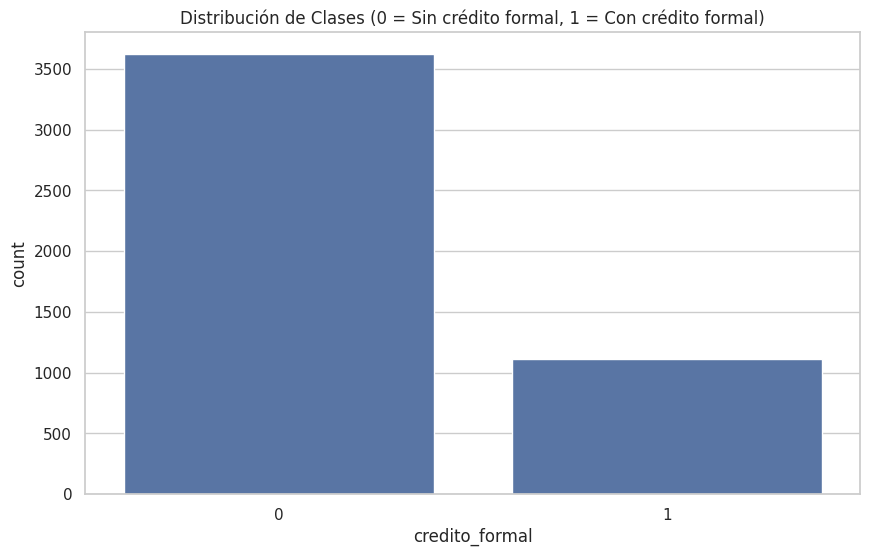

In [7]:
credito_counts = y1.value_counts()
print(credito_counts)
print(f"\nPorcentaje con crédito formal: {credito_counts[1] / credito_counts.sum() * 100:.2f}%")

sns.countplot(x=y1)
plt.title('Distribución de Clases (0 = Sin crédito formal, 1 = Con crédito formal)')
plt.show()

Un modelo que siempre diga "sin crédito" tendría una exactitud cercana al 78 %, pero sería inútil. Por eso usamos **AUC-ROC** como métrica principal y `class_weight='balanced'` para que el modelo penalice más los errores en la clase minoritaria.

### 3.3. División de Datos (Train/Test Split)

**MUY IMPORTANTE:** Dividimos los datos **ANTES** de aplicar cualquier preprocesamiento (escalado, encoding). Esto evita la fuga de datos.

In [8]:
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=42, stratify=y1)

print(f"Forma de X1_train: {X1_train.shape}")
print(f"Forma de X1_test: {X1_test.shape}")
print(f"\nProporción con crédito en y1_train: {y1_train.mean():.2f}")
print(f"Proporción con crédito en y1_test: {y1_test.mean():.2f}")

Forma de X1_train: (3788, 15)
Forma de X1_test: (947, 15)

Proporción con crédito en y1_train: 0.23
Proporción con crédito en y1_test: 0.24


### 3.4. Creación del `ColumnTransformer` (Preprocesador)

1. **Transformador Numérico:** `StandardScaler` a las columnas `num_cols`.
2. **Columnas binarias:** `'passthrough'`, se dejan como 0 y 1.
3. **Transformador Categórico:** `OneHotEncoder` a `ruralidad`, con `drop='first'` (la categoría de referencia es *Ciudades y aglomeraciones*) y `handle_unknown='ignore'`.

El preprocesador va dentro de un `Pipeline` con cada modelo, como en el notebook de KNN y árboles, para que en la validación cruzada el escalado se ajuste solo con los datos de entrenamiento de cada pliegue.

In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('bin', 'passthrough', bin_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ])

### 3.5. Búsqueda de los Mejores Hiperparámetros

Usamos `GridSearchCV` con `cv=5` (Validación Cruzada de 5 pliegues) y `scoring='roc_auc'`.

#### Modelo 1.1: Regresión Logística (con `class_weight`)

**Optimizamos el hiperparámetro `C`**, que controla la fuerza de la regularización. Un C pequeño es una regularización fuerte y un C grande una débil.

In [10]:
print("Iniciando GridSearch para Regresión Logística...")
param_grid_lr = {
    'model__C': [0.01, 0.1, 1, 10]
}

grid_lr_m1 = GridSearchCV(
    Pipeline([('preprocessor', preprocessor),
              ('model', LogisticRegression(random_state=42, class_weight='balanced', max_iter=2000))]),
    param_grid=param_grid_lr,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_lr_m1.fit(X1_train, y1_train)

print(f"\nMejor Puntuación (AUC-ROC) en CV: {grid_lr_m1.best_score_:.4f}")
print(f"Mejores Hiperparámetros: {grid_lr_m1.best_params_}")

Iniciando GridSearch para Regresión Logística...
Fitting 5 folds for each of 4 candidates, totalling 20 fits



Mejor Puntuación (AUC-ROC) en CV: 0.7141
Mejores Hiperparámetros: {'model__C': 0.1}


#### Modelo 1.2: Árbol de Decisión (con `class_weight`)

In [11]:
print("Iniciando GridSearch para Decision Tree...")
param_grid_dt = {
    'model__max_depth': [3, 4, 5, 6, 8],
    'model__min_samples_leaf': [10, 25, 50]
}

grid_dt_m1 = GridSearchCV(
    Pipeline([('preprocessor', preprocessor),
              ('model', DecisionTreeClassifier(random_state=42, class_weight='balanced'))]),
    param_grid=param_grid_dt,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_dt_m1.fit(X1_train, y1_train)

print(f"\nMejor Puntuación (AUC-ROC) en CV: {grid_dt_m1.best_score_:.4f}")
print(f"Mejores Hiperparámetros: {grid_dt_m1.best_params_}")

Iniciando GridSearch para Decision Tree...
Fitting 5 folds for each of 15 candidates, totalling 75 fits



Mejor Puntuación (AUC-ROC) en CV: 0.6887
Mejores Hiperparámetros: {'model__max_depth': 5, 'model__min_samples_leaf': 50}


#### Modelo 1.3: Random Forest (con `class_weight`)

In [12]:
print("Iniciando GridSearch para Random Forest...")
param_grid_rf = {
    'model__n_estimators': [200, 400],
    'model__max_depth': [4, 6, 8],
    'model__min_samples_leaf': [5, 15]
}

grid_rf_m1 = GridSearchCV(
    Pipeline([('preprocessor', preprocessor),
              ('model', RandomForestClassifier(random_state=42, class_weight='balanced'))]),
    param_grid=param_grid_rf,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_rf_m1.fit(X1_train, y1_train)

print(f"\nMejor Puntuación (AUC-ROC) en CV: {grid_rf_m1.best_score_:.4f}")
print(f"Mejores Hiperparámetros: {grid_rf_m1.best_params_}")

Iniciando GridSearch para Random Forest...
Fitting 5 folds for each of 12 candidates, totalling 60 fits



Mejor Puntuación (AUC-ROC) en CV: 0.7188
Mejores Hiperparámetros: {'model__max_depth': 8, 'model__min_samples_leaf': 15, 'model__n_estimators': 400}


#### Modelo 1.4: XGBoost (con `scale_pos_weight`)

El valor ideal de `scale_pos_weight` es `(conteo de la clase mayoritaria) / (conteo de la clase minoritaria)`.

In [13]:
# Calcular scale_pos_weight para el set de ENTRENAMIENTO
counts = y1_train.value_counts()
scale_pos_weight_m1 = counts[0] / counts[1]
print(f"El valor de scale_pos_weight es: {scale_pos_weight_m1:.2f}")

El valor de scale_pos_weight es: 3.26


In [14]:
print("Iniciando GridSearch para XGBoost...")
param_grid_xgb = {
    'model__n_estimators': [150, 300],
    'model__learning_rate': [0.03, 0.08],
    'model__max_depth': [2, 3, 4]
}

grid_xgb_m1 = GridSearchCV(
    Pipeline([('preprocessor', preprocessor),
              ('model', XGBClassifier(random_state=42,
                                      objective='binary:logistic',
                                      eval_metric='logloss',
                                      scale_pos_weight=scale_pos_weight_m1))]),
    param_grid=param_grid_xgb,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_xgb_m1.fit(X1_train, y1_train)

print(f"\nMejor Puntuación (AUC-ROC) en CV: {grid_xgb_m1.best_score_:.4f}")
print(f"Mejores Hiperparámetros: {grid_xgb_m1.best_params_}")

Iniciando GridSearch para XGBoost...
Fitting 5 folds for each of 12 candidates, totalling 60 fits



Mejor Puntuación (AUC-ROC) en CV: 0.7228
Mejores Hiperparámetros: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 300}


### 3.6. Comparación de Modelos

In [15]:
# Recopilar los resultados
results_m1 = {
    'Modelo': [
        'Regresión Logística',
        'Árbol de Decisión',
        'Random Forest',
        'XGBoost'
    ],
    'Mejor_AUC_ROC_CV': [
        grid_lr_m1.best_score_,
        grid_dt_m1.best_score_,
        grid_rf_m1.best_score_,
        grid_xgb_m1.best_score_
    ]
}

df_results_m1 = pd.DataFrame(results_m1).sort_values(by='Mejor_AUC_ROC_CV', ascending=False)

print("Resultados de la Comparación de Modelos (basado en CV en el set de TRAIN):")
display(df_results_m1.style.format({'Mejor_AUC_ROC_CV': '{:.4f}'}))

Resultados de la Comparación de Modelos (basado en CV en el set de TRAIN):


,Modelo,Mejor_AUC_ROC_CV
3,XGBoost,0.7228
2,Random Forest,0.7188
0,Regresión Logística,0.7141
1,Árbol de Decisión,0.6887


### 3.7. Evaluación Final del Modelo Campeón en el Conjunto de Prueba

In [16]:
# Diccionario de modelos para selección automática
model_map_m1 = {
    'Regresión Logística': grid_lr_m1.best_estimator_,
    'Árbol de Decisión': grid_dt_m1.best_estimator_,
    'Random Forest': grid_rf_m1.best_estimator_,
    'XGBoost': grid_xgb_m1.best_estimator_
}

winner_name_m1 = df_results_m1.iloc[0]['Modelo']
best_model_m1 = model_map_m1[winner_name_m1]

print(f"Evaluando el modelo campeón: {winner_name_m1}")

# Realizar predicciones en X1_test
y1_pred_test = best_model_m1.predict(X1_test)
y1_proba_test = best_model_m1.predict_proba(X1_test)[:, 1] # Probabilidades para la clase 1 (Con crédito)

Evaluando el modelo campeón: XGBoost


--- Reporte de Clasificación (Test Set) ---
                 precision    recall  f1-score   support

Sin crédito (0)       0.85      0.67      0.75       724
Con crédito (1)       0.36      0.61      0.45       223

       accuracy                           0.66       947
      macro avg       0.61      0.64      0.60       947
   weighted avg       0.73      0.66      0.68       947

--- Matriz de Confusión (Test Set) ---


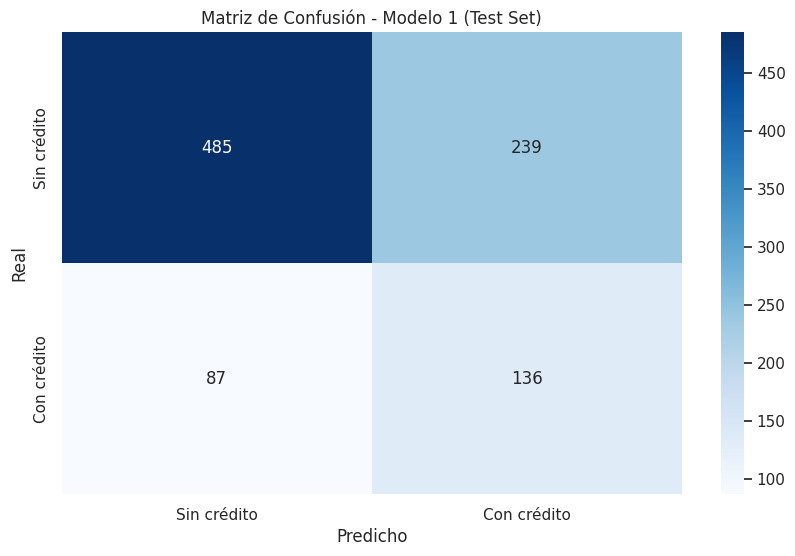

In [17]:
print("--- Reporte de Clasificación (Test Set) ---")
print(classification_report(y1_test, y1_pred_test, target_names=['Sin crédito (0)', 'Con crédito (1)']))

print("--- Matriz de Confusión (Test Set) ---")
cm = confusion_matrix(y1_test, y1_pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Sin crédito', 'Con crédito'], yticklabels=['Sin crédito', 'Con crédito'])
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.title('Matriz de Confusión - Modelo 1 (Test Set)')
guardar('11_matriz_confusion_modelo1')
plt.show()

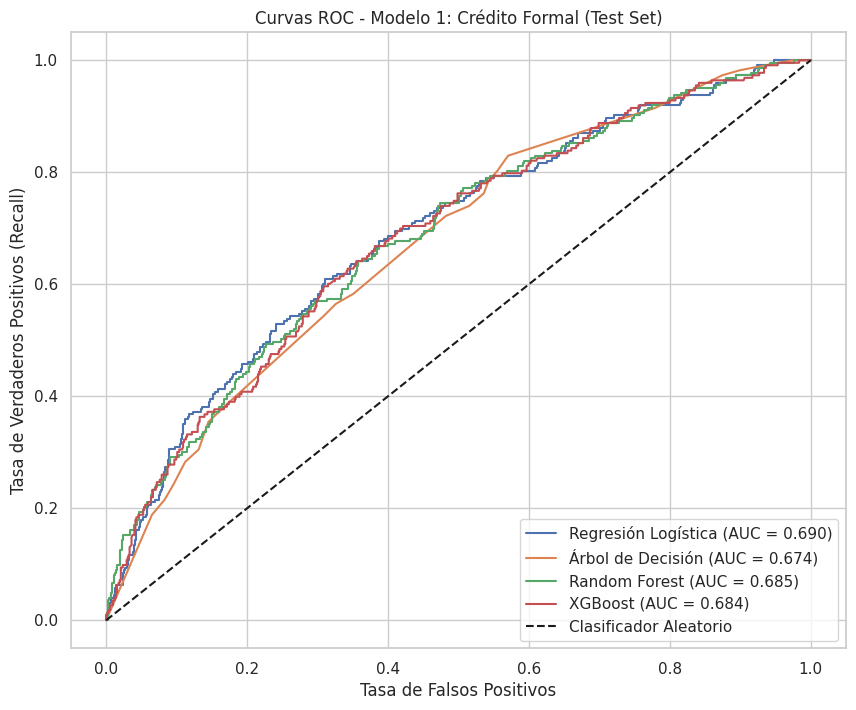

In [18]:
# Curvas ROC de los cuatro modelos en el Test Set
plt.figure(figsize=(10, 8))
for nombre, modelo in model_map_m1.items():
    y_prob = modelo.predict_proba(X1_test)[:, 1]
    fpr, tpr, _ = roc_curve(y1_test, y_prob)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc_score(y1_test, y_prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.title('Curvas ROC - Modelo 1: Crédito Formal (Test Set)')
plt.legend(loc='lower right')
guardar('10_roc_modelo1')
plt.show()

**Interpretación:** en la validación cruzada gana XGBoost con un AUC de 0,723, seguido de Random Forest (0,719) y la regresión logística (0,714). El árbol de decisión individual queda último (0,689), como se esperaba frente a los ensambles. Las diferencias entre los tres primeros son muy pequeñas.

En el conjunto de prueba los AUC bajan un poco, a cerca de 0,69 en los tres primeros. Esa caída es normal por el tamaño de la muestra de prueba (947 personas) y no cambia la conclusión: los modelos discriminan mejor que el azar, pero no de forma perfecta.

El modelo campeón identifica al 61 % de quienes tienen crédito formal (recall de la clase 1), y de los que marca como "con crédito", el 36 % lo tiene (precisión). Esto quiere decir que las características de partida explican una parte del acceso, pero no todo: quedan factores que la encuesta no mide, como el historial con el banco o la oferta de entidades en el municipio.

Como la regresión logística rinde casi igual que los ensambles y es mucho más fácil de interpretar, la usamos para leer la dirección y el tamaño de cada variable, y SHAP sobre Random Forest para confirmar la importancia.

### 3.8. Interpretación de los Coeficientes (Regresión Logística)

Igual que en el notebook de regresión logística: el coeficiente es un logaritmo de odds, y el **Odds Ratio** (`np.exp(coef)`) dice por cuánto se multiplican los odds de tener crédito formal. Para las variables numéricas, que están estandarizadas, el cambio es por una desviación estándar. Para las binarias y la ruralidad, es frente a no tener la característica o frente a vivir en *Ciudades y aglomeraciones*.

In [19]:
# Nombres de las variables después del preprocesamiento
# (se quita el prefijo 'num__', 'bin__' o 'cat__' que agrega el ColumnTransformer)
feature_names_m1 = [n.split('__')[1] for n in grid_lr_m1.best_estimator_.named_steps['preprocessor'].get_feature_names_out()]

# Creamos un DataFrame para ver los coeficientes
coeficientes_m1 = pd.DataFrame({
    'Variable': feature_names_m1,
    'Coeficiente': grid_lr_m1.best_estimator_.named_steps['model'].coef_[0]
})
# Calculamos el Odds Ratio (más fácil de interpretar)
coeficientes_m1['Odds_Ratio'] = np.exp(coeficientes_m1['Coeficiente'])

# Ordenamos por el valor del coeficiente para ver los más influyentes
coeficientes_m1 = coeficientes_m1.sort_values(by='Odds_Ratio', ascending=False)
coeficientes_m1

,Variable,Coeficiente,Odds_Ratio
15,ruralidad_Rural,0.52,1.68
6,ocupado,0.42,1.52
0,ingreso_smmlv,0.40,1.49
2,edad,0.33,1.38
12,usa_internet,0.30,1.35
1,indice_activos,0.30,1.35
16,ruralidad_Rural disperso,0.21,1.23
3,educ_orden,0.18,1.20
8,trabaja_agro,0.09,1.09
11,jefe_hogar,0.08,1.09


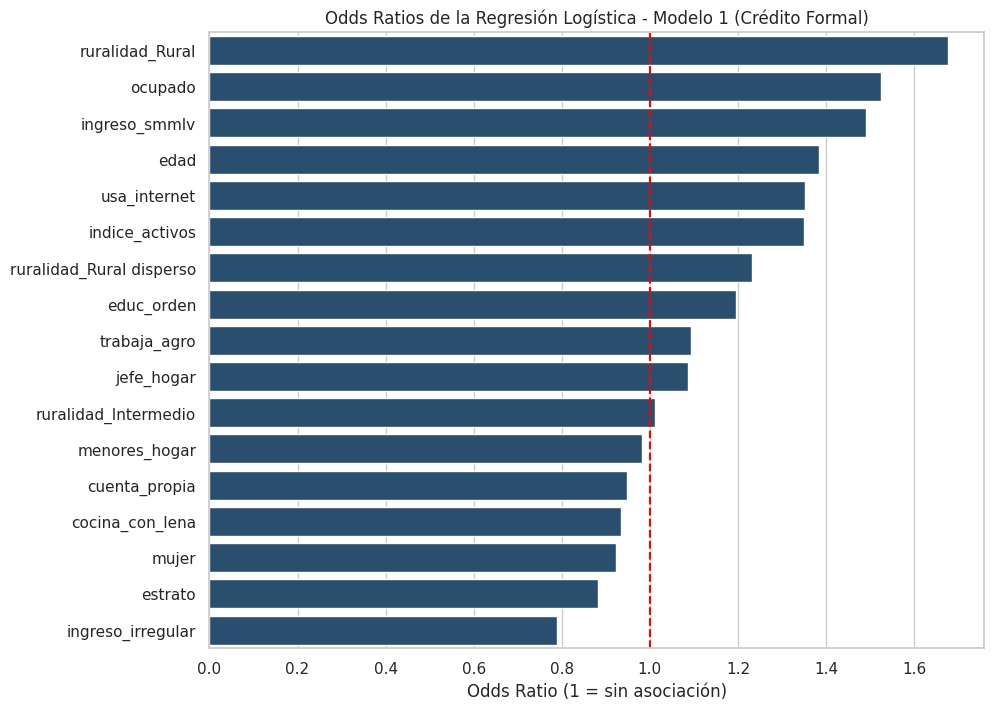

In [20]:
plt.figure(figsize=(10, 8))
sns.barplot(x='Odds_Ratio', y='Variable', data=coeficientes_m1, color='#1f4e79')
plt.axvline(1, color='red', linestyle='--')
plt.title('Odds Ratios de la Regresión Logística - Modelo 1 (Crédito Formal)')
plt.xlabel('Odds Ratio (1 = sin asociación)')
plt.ylabel('')
guardar('12_odds_ratios_modelo1')
plt.show()

**Interpretación:**

- **Ruralidad:** manteniendo todo lo demás constante, vivir en un municipio rural multiplica los odds de tener crédito formal por 1,68 frente a las ciudades, y vivir en uno rural disperso por 1,23. En los municipios intermedios el odds ratio es 1,01, prácticamente igual a las ciudades.
- **Capacidad de pago:** estar ocupado multiplica los odds por 1,52, y una desviación estándar más de ingreso, de edad, de activos y de educación los multiplica por 1,49, 1,38, 1,35 y 1,20.
- **Conectividad:** usar internet los multiplica por 1,35.
- **Riesgo percibido:** tener ingresos irregulares reduce los odds en 21 % (0,79).

**Qué significa:** el modelo confirma el hallazgo del EDA con todas las variables al tiempo. La desventaja rural en el acceso al crédito **no se debe a la ruralidad en sí**, sino a que los hogares rurales tienen menos ingreso, menos empleo y menos conectividad. Cuando se compara a personas con las mismas condiciones, vivir en un municipio rural se asocia con **más** crédito formal, lo que es consistente con el papel de las cooperativas, a las que acude el 27,6 % de los solicitantes rurales según el EDA. La penalización a los ingresos irregulares es la señal del racionamiento de crédito de Stiglitz y Weiss (1981): al prestamista le cuesta evaluar el riesgo de quien no tiene un ingreso estable.

### 3.9. Análisis de Interpretabilidad con SHAP (Random Forest)

Como en el notebook de ensambles, SHAP nos muestra no solo qué variables son las más importantes sino en qué dirección mueven la predicción.

Importancia Global de las Variables (SHAP)


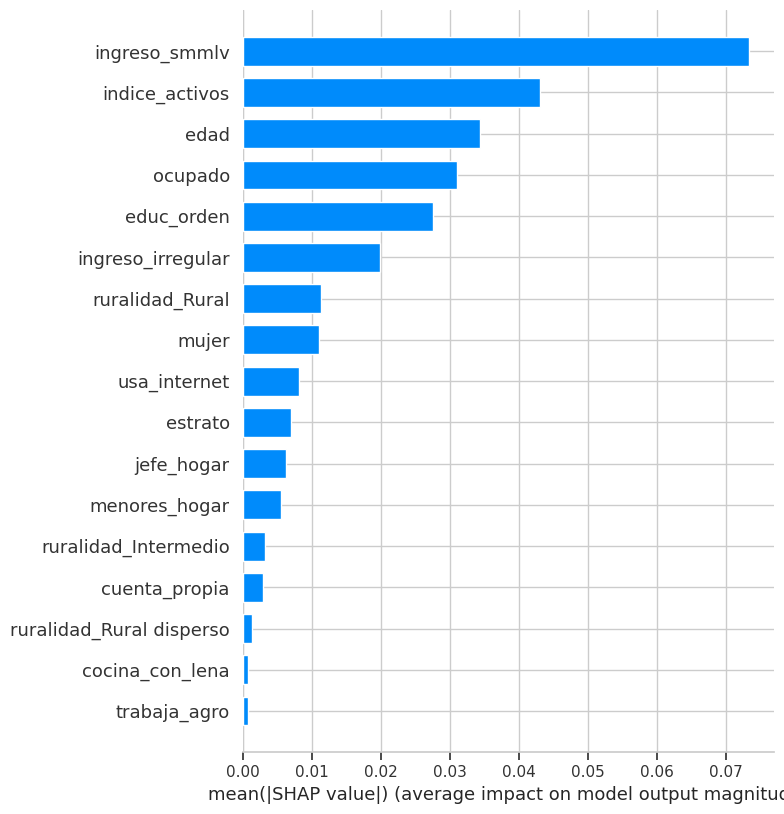

In [21]:
# Modelo Random Forest optimizado y datos de prueba ya transformados
rf_m1 = grid_rf_m1.best_estimator_
X1_test_transformed = rf_m1.named_steps['preprocessor'].transform(X1_test)

# 1. Crear el explainer y calcular los valores SHAP
explainer_m1 = shap.TreeExplainer(rf_m1.named_steps['model'])
shap_values_m1 = explainer_m1.shap_values(X1_test_transformed)

# 2. Extraer solo los valores de la clase 1 (Con crédito)
# El formato es [todas_las_filas, todas_las_columnas, indice_clase]
shap_credito = shap_values_m1[:, :, 1]

# 3. Gráfico de barras (Importancia Global)
print("Importancia Global de las Variables (SHAP)")
shap.summary_plot(shap_credito, X1_test_transformed, plot_type="bar", feature_names=feature_names_m1)

Impacto Direccional de cada Variable (SHAP)


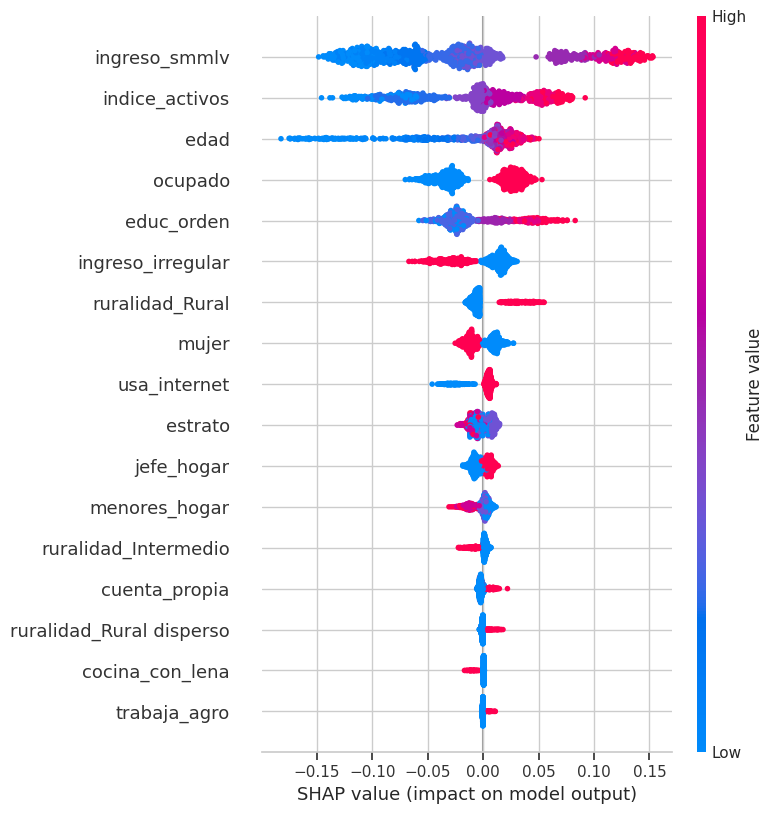

In [22]:
# 4. Gráfico de puntos (Impacto Direccional)
print("Impacto Direccional de cada Variable (SHAP)")
shap.summary_plot(shap_credito, X1_test_transformed, feature_names=feature_names_m1, show=False)
guardar('13_shap_modelo1')
plt.show()

**Interpretación:** en Random Forest la variable más importante es el **ingreso del hogar**, seguida de los activos, la edad, estar ocupado y la educación. Los valores altos de ingreso (puntos rojos) empujan hacia la derecha, es decir, hacia tener crédito. La ruralidad aparece en el séptimo lugar, con un peso pequeño.

Los dos métodos coinciden en que el acceso al crédito formal depende sobre todo de la **capacidad de pago** y del colateral (ingreso, activos y empleo), y no del territorio. Para la política pública esto quiere decir que ampliar la oferta en zonas rurales no basta si los hogares no tienen ingresos estables con los cuales responder.

---
## 4. Modelo 2: ¿El crédito formal se asocia con más resiliencia en los hogares rurales?

En el EDA, la medida de bienestar que sí mostró diferencias entre quienes tienen y no tienen crédito fue la **resiliencia**: poder vivir un mes o más con ahorros o vendiendo activos si se dejan de recibir ingresos. El índice de bienestar percibido casi no cambiaba y tiene una consistencia interna moderada (alfa de Cronbach de 0,63).

Agregamos tres variables financieras a las mismas características de partida: crédito formal, crédito informal y ahorro formal. La pregunta clave es si el **crédito formal** sigue siendo relevante cuando el modelo ya conoce el ingreso, los activos, la educación y el empleo.

### 4.1. Definición de X/y

In [23]:
fin_cols = ['credito_formal', 'credito_informal', 'ahorro_formal']
bin_cols_m2 = fin_cols + bin_cols

# Solo municipios rurales y rurales dispersos
rural = df[df['rural'] == 1]
df_m2 = rural[num_cols + bin_cols_m2 + cat_cols + ['aguanta_un_mes_o_mas']].dropna()
print(f"Adultos rurales: {rural.shape[0]} | Filas después de eliminar nulos: {df_m2.shape[0]}")

X2 = df_m2.drop('aguanta_un_mes_o_mas', axis=1)
y2 = df_m2['aguanta_un_mes_o_mas'].astype(int)

print(y2.value_counts(normalize=True))

Adultos rurales: 1289 | Filas después de eliminar nulos: 1005
aguanta_un_mes_o_mas
1   0.64
0   0.36
Name: proportion, dtype: float64


### 4.2. División de Datos y Preprocesador

In [24]:
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42, stratify=y2)

print(f"Forma de X2_train: {X2_train.shape}")
print(f"Forma de X2_test: {X2_test.shape}")

preprocessor_m2 = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('bin', 'passthrough', bin_cols_m2),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), cat_cols)
    ])

Forma de X2_train: (804, 18)
Forma de X2_test: (201, 18)


### 4.3. Búsqueda de los Mejores Hiperparámetros

#### Modelo 2.1: Regresión Logística (con `class_weight`)

In [25]:
print("Iniciando GridSearch para Regresión Logística...")
grid_lr_m2 = GridSearchCV(
    Pipeline([('preprocessor', preprocessor_m2),
              ('model', LogisticRegression(random_state=42, class_weight='balanced', max_iter=2000))]),
    param_grid=param_grid_lr,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_lr_m2.fit(X2_train, y2_train)

print(f"\nMejor Puntuación (AUC-ROC) en CV: {grid_lr_m2.best_score_:.4f}")
print(f"Mejores Hiperparámetros: {grid_lr_m2.best_params_}")

Iniciando GridSearch para Regresión Logística...
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Mejor Puntuación (AUC-ROC) en CV: 0.6430
Mejores Hiperparámetros: {'model__C': 0.01}


#### Modelo 2.2: Árbol de Decisión (con `class_weight`)

In [26]:
print("Iniciando GridSearch para Decision Tree...")
grid_dt_m2 = GridSearchCV(
    Pipeline([('preprocessor', preprocessor_m2),
              ('model', DecisionTreeClassifier(random_state=42, class_weight='balanced'))]),
    param_grid=param_grid_dt,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_dt_m2.fit(X2_train, y2_train)

print(f"\nMejor Puntuación (AUC-ROC) en CV: {grid_dt_m2.best_score_:.4f}")
print(f"Mejores Hiperparámetros: {grid_dt_m2.best_params_}")

Iniciando GridSearch para Decision Tree...


Fitting 5 folds for each of 15 candidates, totalling 75 fits



Mejor Puntuación (AUC-ROC) en CV: 0.5958
Mejores Hiperparámetros: {'model__max_depth': 3, 'model__min_samples_leaf': 50}


#### Modelo 2.3: Random Forest (con `class_weight`)

In [27]:
print("Iniciando GridSearch para Random Forest...")
grid_rf_m2 = GridSearchCV(
    Pipeline([('preprocessor', preprocessor_m2),
              ('model', RandomForestClassifier(random_state=42, class_weight='balanced'))]),
    param_grid=param_grid_rf,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_rf_m2.fit(X2_train, y2_train)

print(f"\nMejor Puntuación (AUC-ROC) en CV: {grid_rf_m2.best_score_:.4f}")
print(f"Mejores Hiperparámetros: {grid_rf_m2.best_params_}")

Iniciando GridSearch para Random Forest...
Fitting 5 folds for each of 12 candidates, totalling 60 fits



Mejor Puntuación (AUC-ROC) en CV: 0.6438
Mejores Hiperparámetros: {'model__max_depth': 6, 'model__min_samples_leaf': 15, 'model__n_estimators': 200}


#### Modelo 2.4: XGBoost (con `scale_pos_weight`)

In [28]:
# Calcular scale_pos_weight para el set de ENTRENAMIENTO
counts = y2_train.value_counts()
scale_pos_weight_m2 = counts[0] / counts[1]
print(f"El valor de scale_pos_weight es: {scale_pos_weight_m2:.2f}")

print("Iniciando GridSearch para XGBoost...")
grid_xgb_m2 = GridSearchCV(
    Pipeline([('preprocessor', preprocessor_m2),
              ('model', XGBClassifier(random_state=42,
                                      objective='binary:logistic',
                                      eval_metric='logloss',
                                      scale_pos_weight=scale_pos_weight_m2))]),
    param_grid=param_grid_xgb,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_xgb_m2.fit(X2_train, y2_train)

print(f"\nMejor Puntuación (AUC-ROC) en CV: {grid_xgb_m2.best_score_:.4f}")
print(f"Mejores Hiperparámetros: {grid_xgb_m2.best_params_}")

El valor de scale_pos_weight es: 0.56
Iniciando GridSearch para XGBoost...
Fitting 5 folds for each of 12 candidates, totalling 60 fits



Mejor Puntuación (AUC-ROC) en CV: 0.6296
Mejores Hiperparámetros: {'model__learning_rate': 0.08, 'model__max_depth': 4, 'model__n_estimators': 150}


**Nota:** en este modelo la clase mayoritaria es la 1 (aguanta un mes o más), así que `scale_pos_weight` queda por debajo de 1 y le da un poco menos de peso a la clase positiva, que es lo correcto para balancear.

### 4.4. Comparación de Modelos

In [29]:
results_m2 = {
    'Modelo': [
        'Regresión Logística',
        'Árbol de Decisión',
        'Random Forest',
        'XGBoost'
    ],
    'Mejor_AUC_ROC_CV': [
        grid_lr_m2.best_score_,
        grid_dt_m2.best_score_,
        grid_rf_m2.best_score_,
        grid_xgb_m2.best_score_
    ]
}

df_results_m2 = pd.DataFrame(results_m2).sort_values(by='Mejor_AUC_ROC_CV', ascending=False)

print("Resultados de la Comparación de Modelos (basado en CV en el set de TRAIN):")
display(df_results_m2.style.format({'Mejor_AUC_ROC_CV': '{:.4f}'}))

Resultados de la Comparación de Modelos (basado en CV en el set de TRAIN):


,Modelo,Mejor_AUC_ROC_CV
2,Random Forest,0.6438
0,Regresión Logística,0.6430
3,XGBoost,0.6296
1,Árbol de Decisión,0.5958


### 4.5. Evaluación Final del Modelo Campeón en el Conjunto de Prueba

In [30]:
model_map_m2 = {
    'Regresión Logística': grid_lr_m2.best_estimator_,
    'Árbol de Decisión': grid_dt_m2.best_estimator_,
    'Random Forest': grid_rf_m2.best_estimator_,
    'XGBoost': grid_xgb_m2.best_estimator_
}

winner_name_m2 = df_results_m2.iloc[0]['Modelo']
best_model_m2 = model_map_m2[winner_name_m2]

print(f"Evaluando el modelo campeón: {winner_name_m2}")

y2_pred_test = best_model_m2.predict(X2_test)
y2_proba_test = best_model_m2.predict_proba(X2_test)[:, 1] # Probabilidades para la clase 1 (Aguanta un mes o más)

Evaluando el modelo campeón: Random Forest


--- Reporte de Clasificación (Test Set) ---
                     precision    recall  f1-score   support

Menos de un mes (0)       0.44      0.60      0.51        72
   Un mes o más (1)       0.72      0.58      0.64       129

           accuracy                           0.59       201
          macro avg       0.58      0.59      0.58       201
       weighted avg       0.62      0.59      0.60       201

--- Matriz de Confusión (Test Set) ---


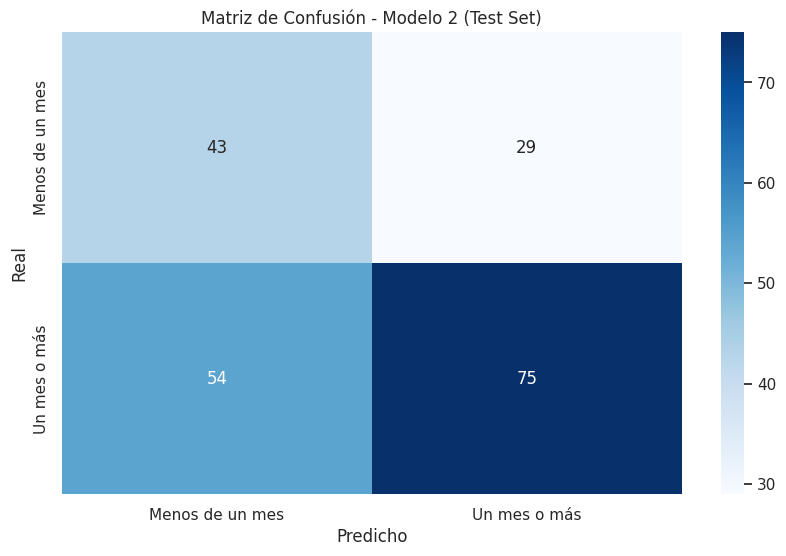

In [31]:
print("--- Reporte de Clasificación (Test Set) ---")
print(classification_report(y2_test, y2_pred_test, target_names=['Menos de un mes (0)', 'Un mes o más (1)']))

print("--- Matriz de Confusión (Test Set) ---")
cm = confusion_matrix(y2_test, y2_pred_test)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Menos de un mes', 'Un mes o más'], yticklabels=['Menos de un mes', 'Un mes o más'])
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.title('Matriz de Confusión - Modelo 2 (Test Set)')
guardar('15_matriz_confusion_modelo2')
plt.show()

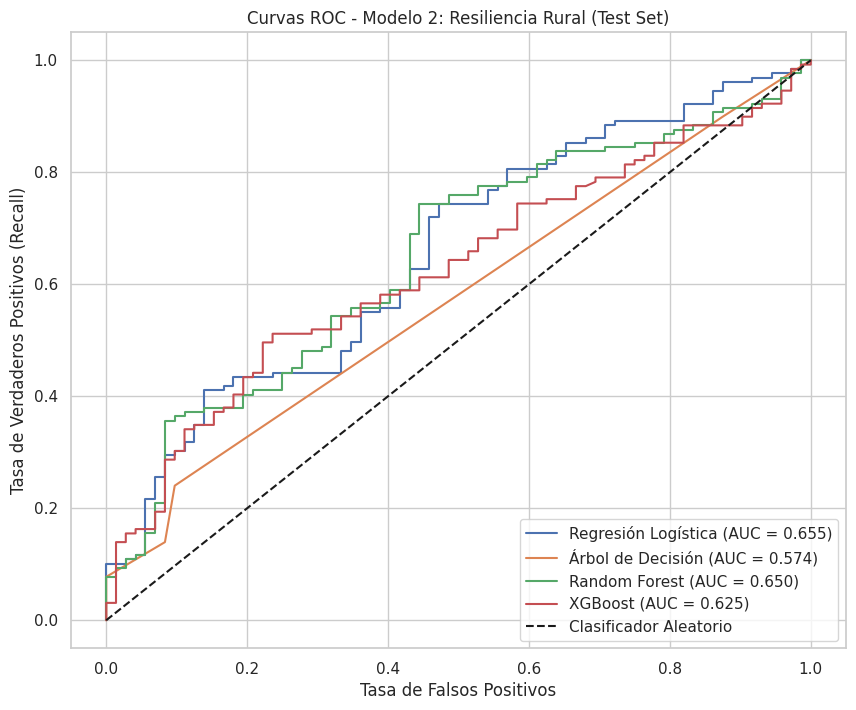

In [32]:
plt.figure(figsize=(10, 8))
for nombre, modelo in model_map_m2.items():
    y_prob = modelo.predict_proba(X2_test)[:, 1]
    fpr, tpr, _ = roc_curve(y2_test, y_prob)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC = {roc_auc_score(y2_test, y_prob):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Clasificador Aleatorio')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos (Recall)')
plt.title('Curvas ROC - Modelo 2: Resiliencia Rural (Test Set)')
plt.legend(loc='lower right')
guardar('14_roc_modelo2')
plt.show()

**Interpretación:** en la validación cruzada Random Forest (0,644) y la regresión logística (0,643) quedan prácticamente empatados, seguidos de XGBoost (0,630) y el árbol (0,596). En prueba la logística llega a 0,655 y Random Forest a 0,650.

El poder predictivo es **modesto**: el modelo campeón identifica al 58 % de quienes sí aguantarían un mes o más sin ingresos, con una precisión del 72 %. La resiliencia de un hogar rural depende en buena parte de cosas que la encuesta no observa, como ahorros no declarados, redes familiares o la posibilidad de vender una cosecha. Por eso el objetivo de este modelo no es predecir con precisión, sino medir **cuánto pesa el crédito formal frente a las demás variables**.

### 4.6. ¿Cuánto de la asociación con el crédito es selección?

Comparamos el **Odds Ratio** del crédito formal en dos regresiones logísticas entrenadas con los mismos datos de entrenamiento:

1. **Sin controles:** solo el crédito formal.
2. **Con controles:** el crédito formal más todas las demás variables del modelo.

Si el Odds Ratio baja mucho al agregar los controles, quiere decir que buena parte de la diferencia en resiliencia se explica por **quiénes** obtienen crédito (selección), y no por el crédito.

In [33]:
# 1. Sin controles: solo el crédito formal
log_sin = LogisticRegression(random_state=42, max_iter=2000)
log_sin.fit(X2_train[['credito_formal']], y2_train)
or_sin_controles = np.exp(log_sin.coef_[0][0])

# 2. Con controles: todas las variables, con el mismo preprocesador
log_con = Pipeline([('preprocessor', preprocessor_m2),
                    ('model', LogisticRegression(random_state=42, max_iter=2000))])
log_con.fit(X2_train, y2_train)
nombres_m2 = [n.split('__')[1] for n in log_con.named_steps['preprocessor'].get_feature_names_out()]
or_con_controles = np.exp(log_con.named_steps['model'].coef_[0][nombres_m2.index('credito_formal')])

seleccion = pd.DataFrame({
    'Especificación': ['Sin controles', 'Con controles'],
    'Odds_Ratio_credito_formal': [or_sin_controles, or_con_controles]
})
seleccion

,Especificación,Odds_Ratio_credito_formal
0,Sin controles,1.68
1,Con controles,1.33


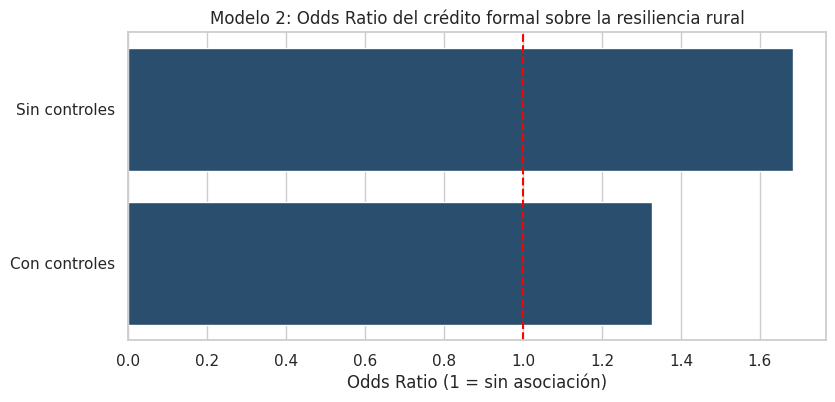

In [34]:
plt.figure(figsize=(9, 4))
sns.barplot(x='Odds_Ratio_credito_formal', y='Especificación', data=seleccion, color='#1f4e79')
plt.axvline(1, color='red', linestyle='--')
plt.title('Modelo 2: Odds Ratio del crédito formal sobre la resiliencia rural')
plt.xlabel('Odds Ratio (1 = sin asociación)')
plt.ylabel('')
guardar('16_seleccion_credito_resiliencia')
plt.show()

In [35]:
# Coeficientes completos del modelo con controles
coeficientes_m2 = pd.DataFrame({
    'Variable': nombres_m2,
    'Coeficiente': log_con.named_steps['model'].coef_[0]
})
coeficientes_m2['Odds_Ratio'] = np.exp(coeficientes_m2['Coeficiente'])
coeficientes_m2.sort_values(by='Odds_Ratio', ascending=False)

,Variable,Coeficiente,Odds_Ratio
8,ahorro_formal,0.52,1.69
11,trabaja_agro,0.48,1.62
6,credito_formal,0.28,1.33
0,ingreso_smmlv,0.25,1.28
3,educ_orden,0.23,1.26
15,usa_internet,0.17,1.18
14,jefe_hogar,0.15,1.16
1,indice_activos,0.10,1.11
17,ruralidad_Rural disperso,0.09,1.09
9,ocupado,0.08,1.08


**Interpretación:** sin controles, tener crédito formal multiplica los odds de aguantar un mes o más sin ingresos por 1,68. Es la diferencia que vimos en el EDA: en esta muestra, el 73 % de los rurales con crédito podría vivir un mes o más sin ingresos, frente al 61 % de los que no tienen. Al controlar por ingreso, activos, educación, empleo y las demás características, el odds ratio baja a 1,33.

**Qué significa:** cerca de **la mitad de la ventaja** asociada al crédito (de +68 % a +33 % en los odds) se explica por quiénes lo obtienen, es decir, por **selección**. La asociación que queda sigue siendo positiva, pero es más pequeña, y con estos datos no se puede afirmar que el crédito cause más resiliencia: también puede ser al revés, que los hogares con más colchón financiero sean los que se atreven a endeudarse.

En el modelo con controles también se ve que el ahorro formal (1,69) y trabajar en el agro (1,62) se asocian con más resiliencia, mientras que el crédito informal (0,65) y ser mujer (0,78) se asocian con menos.

### 4.7. Análisis de Interpretabilidad con SHAP (Random Forest)

Importancia Global de las Variables (SHAP)


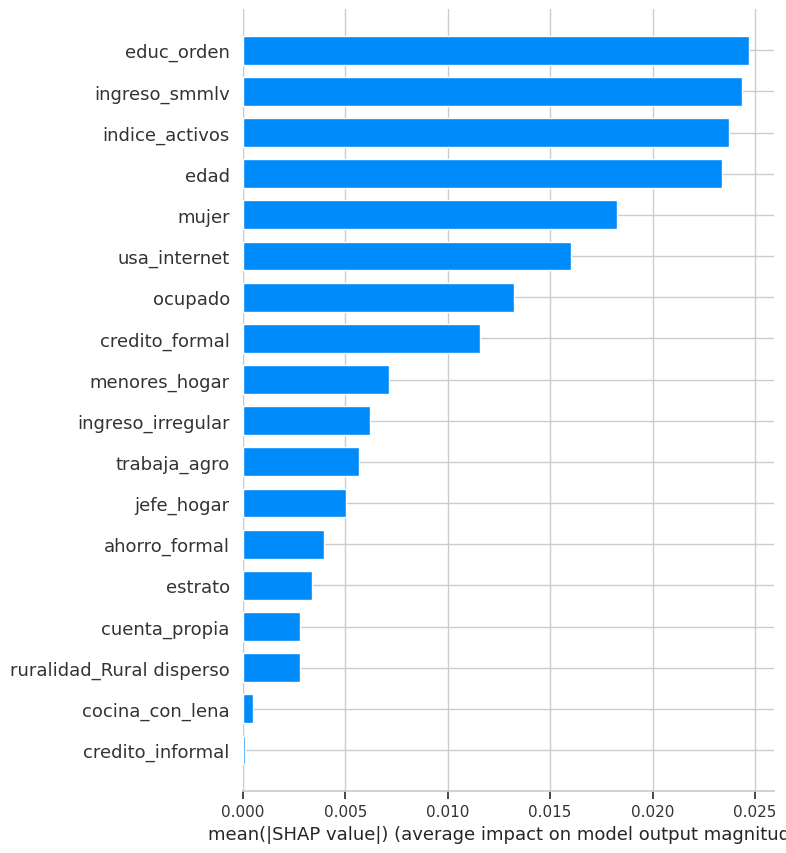

In [36]:
rf_m2 = grid_rf_m2.best_estimator_
X2_test_transformed = rf_m2.named_steps['preprocessor'].transform(X2_test)
feature_names_m2 = [n.split('__')[1] for n in rf_m2.named_steps['preprocessor'].get_feature_names_out()]

# 1. Crear el explainer y calcular los valores SHAP
explainer_m2 = shap.TreeExplainer(rf_m2.named_steps['model'])
shap_values_m2 = explainer_m2.shap_values(X2_test_transformed)

# 2. Extraer solo los valores de la clase 1 (Aguanta un mes o más)
shap_resiliencia = shap_values_m2[:, :, 1]

# 3. Gráfico de barras (Importancia Global)
print("Importancia Global de las Variables (SHAP)")
shap.summary_plot(shap_resiliencia, X2_test_transformed, plot_type="bar", feature_names=feature_names_m2)

Impacto Direccional de cada Variable (SHAP)


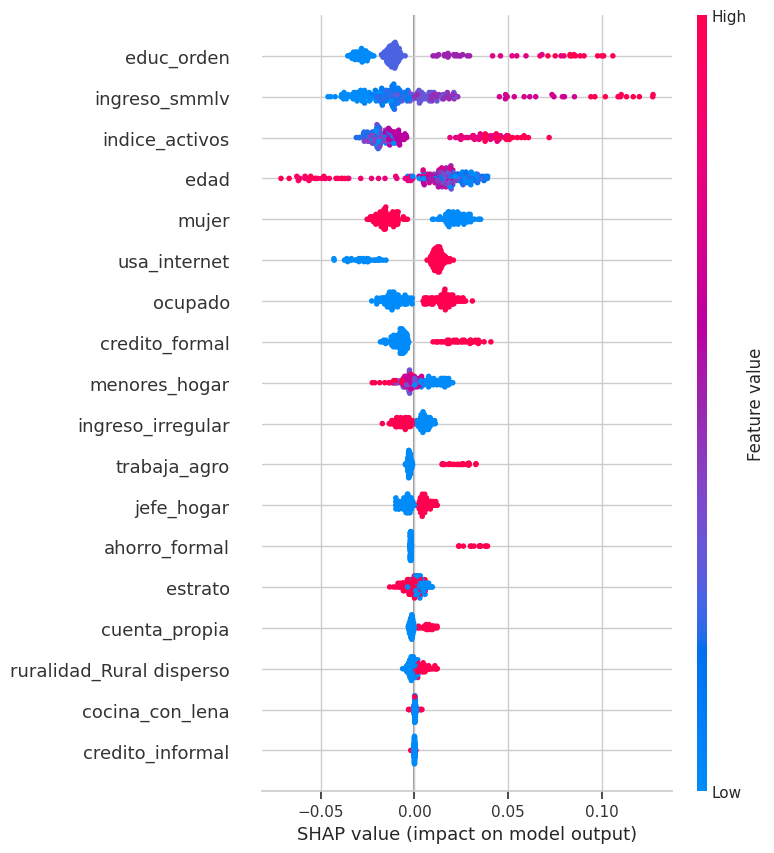

In [37]:
# 4. Gráfico de puntos (Impacto Direccional)
print("Impacto Direccional de cada Variable (SHAP)")
shap.summary_plot(shap_resiliencia, X2_test_transformed, feature_names=feature_names_m2, show=False)
guardar('17_shap_modelo2')
plt.show()

In [38]:
# Ranking de importancia (promedio del valor absoluto de SHAP)
importancia_m2 = pd.DataFrame({'Variable': feature_names_m2,
                               'SHAP_medio': np.abs(shap_resiliencia).mean(axis=0)}).sort_values('SHAP_medio', ascending=False)
importancia_m2['Puesto'] = range(1, len(importancia_m2) + 1)
importancia_m2

,Variable,SHAP_medio,Puesto
3,educ_orden,0.02,1
0,ingreso_smmlv,0.02,2
1,indice_activos,0.02,3
2,edad,0.02,4
13,mujer,0.02,5
15,usa_internet,0.02,6
9,ocupado,0.01,7
6,credito_formal,0.01,8
5,menores_hogar,0.01,9
12,ingreso_irregular,0.01,10


**Interpretación:** en Random Forest, las variables que más mueven la probabilidad de aguantar un mes o más sin ingresos son la educación, el ingreso, los activos, la edad y el sexo. El crédito formal aparece en el **octavo lugar**, con una importancia pequeña.

Los dos enfoques llevan a la misma conclusión: en los hogares rurales, la capacidad de enfrentar un choque de ingreso depende sobre todo del **nivel de ingreso, la educación y los activos**, y el crédito formal agrega poco una vez se tiene eso en cuenta. Esto responde la pregunta abierta del EDA: la inclusión crediticia rural está llegando principalmente a los hogares que ya estaban en mejores condiciones.

---
## 5. Conclusiones de los modelos

1. **Acceso (Modelo 1):** el crédito formal depende de la capacidad de pago (ingreso, activos, empleo, educación) y de la conectividad. Con las mismas características, vivir en un municipio rural **no reduce** las probabilidades de tener crédito: las aumenta (odds ratio de 1,68). La desventaja rural pasa por el ingreso.
2. **Bienestar (Modelo 2):** la asociación entre crédito formal y resiliencia rural se reduce a la mitad al controlar por las condiciones de partida (de 1,68 a 1,33). El ingreso, la educación y los activos son los que más explican la resiliencia.
3. **Modelos:** los ensambles no superan claramente a la regresión logística en ninguno de los dos problemas. Con variables de encuesta y relaciones casi monotónicas, el modelo más simple es igual de bueno y más interpretable.

---
## 6. Exportación de resultados

In [39]:
with pd.ExcelWriter('outputs/tables/tablas_modelos.xlsx') as writer:
    df_results_m1.to_excel(writer, sheet_name='M1 comparacion', index=False)
    coeficientes_m1.to_excel(writer, sheet_name='M1 odds ratios', index=False)
    df_results_m2.to_excel(writer, sheet_name='M2 comparacion', index=False)
    coeficientes_m2.to_excel(writer, sheet_name='M2 odds ratios', index=False)
    seleccion.to_excel(writer, sheet_name='M2 seleccion', index=False)
    importancia_m2.to_excel(writer, sheet_name='M2 SHAP', index=False)
print('Tablas guardadas en outputs/tables/tablas_modelos.xlsx')

Tablas guardadas en outputs/tables/tablas_modelos.xlsx


In [40]:
# requirements.txt con las versiones exactas de las librerías que usan los dos notebooks
from importlib.metadata import version
librerias = ['pandas', 'numpy', 'matplotlib', 'seaborn', 'scipy', 'openpyxl', 'requests', 'scikit-learn', 'xgboost', 'shap']
with open('requirements.txt', 'w') as f:
    for lib in librerias:
        f.write(f'{lib}=={version(lib)}\n')
print(open('requirements.txt').read())

pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0
seaborn==0.13.2
scipy==1.16.3
openpyxl==3.1.5
requests==2.32.4
scikit-learn==1.6.1
xgboost==2.1.4
shap==0.48.0

